<a href="https://colab.research.google.com/github/harship123-source/NEUR-3002/blob/Homeworks/ClusteringActivity.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
!pip install spacy scikit-learn matplotlib seaborn ipywidgets
!python -m spacy download en_core_web_md

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 33.5/33.5 MB 107.3 MB/s  0:00:00
✔ Download and installation successful
You can now load the package via spacy.load('en_core_web_md')
⚠ Restart to reload dependencies
If you are in a Jupyter or Colab notebook, you may need to restart Python in
order to load all the package's dependencies. You can do this by selecting the
'Restart kernel' or 'Restart runtime' option.


In [2]:
import os
os.environ["OMP_NUM_THREADS"] = "1"


📊 Cluster Assignments:
         Word  Cluster     PCA_1     PCA_2
0       apple        3  3.471315  1.435617
1      banana        3  3.471315  1.435617
2       grape        3  3.357685  1.070662
3        king        2 -4.624590  2.715040
4       queen        0 -3.018396 -1.654781
5      prince        2 -4.624590  2.715040
6        frog        1 -0.679217 -4.022590
7  strawberry        3  3.325696  0.327986
8       snake        1 -0.679217 -4.022590


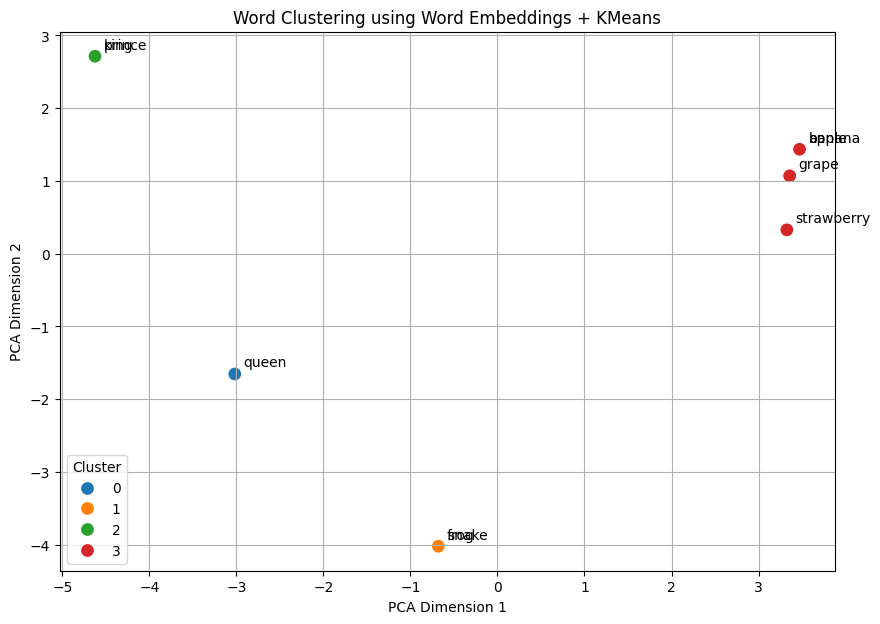

In [7]:
# 📦 Imports
import spacy
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
import pandas as pd

# 🧠 Load spaCy's medium English model (includes word vectors)
nlp = spacy.load("en_core_web_md")

# ✍️ Input: List of words to cluster
words = ["apple", "banana", "grape", "king", "queen", "prince", 'frog', 'strawberry', 'snake']

# 🔢 Extract word vectors
word_vectors = [nlp(word).vector for word in words]

# ⚙️ Clustering using KMeans
k = 4  # Number of clusters — adjust as needed
kmeans = KMeans(n_clusters=k, random_state=0, n_init="auto")
labels = kmeans.fit_predict(word_vectors)

# 🔍 Reduce dimensions for visualization (2D)
pca = PCA(n_components=2)
points_2d = pca.fit_transform(word_vectors)

# 🧾 Show cluster assignments as a table
df = pd.DataFrame({
    "Word": words,
    "Cluster": labels,
    "PCA_1": points_2d[:, 0],
    "PCA_2": points_2d[:, 1]
})
print("📊 Cluster Assignments:")
print(df)

# 🎨 Plot the clustered words
plt.figure(figsize=(10, 7))
sns.scatterplot(x=points_2d[:, 0], y=points_2d[:, 1], hue=labels, palette="tab10", s=100)

# Annotate each point with the word
for i, word in enumerate(words):
    plt.text(points_2d[i, 0]+0.1, points_2d[i, 1]+0.1, word)

plt.title("Word Clustering using Word Embeddings + KMeans")
plt.xlabel("PCA Dimension 1")
plt.ylabel("PCA Dimension 2")
plt.legend(title="Cluster")
plt.grid(True)
plt.show()





Noise added to script


Baseline clusters: [['apple', 'banana', 'grape', 'strawberry'], ['frog', 'snake'], ['king', 'prince'], ['queen']]
Vector std per dimension (avg): 0.396
 noise (x data std)  mean ARI  % runs identical to baseline
               0.10     1.000                           100
               0.25     1.000                           100
               0.50     0.979                            95
               1.00     0.863                            70
               2.00     0.514                             5

Noisy (0.5 std) clusters: [['apple', 'banana', 'grape', 'strawberry'], ['frog', 'snake'], ['king', 'prince'], ['queen']]
ARI vs baseline: 1.0


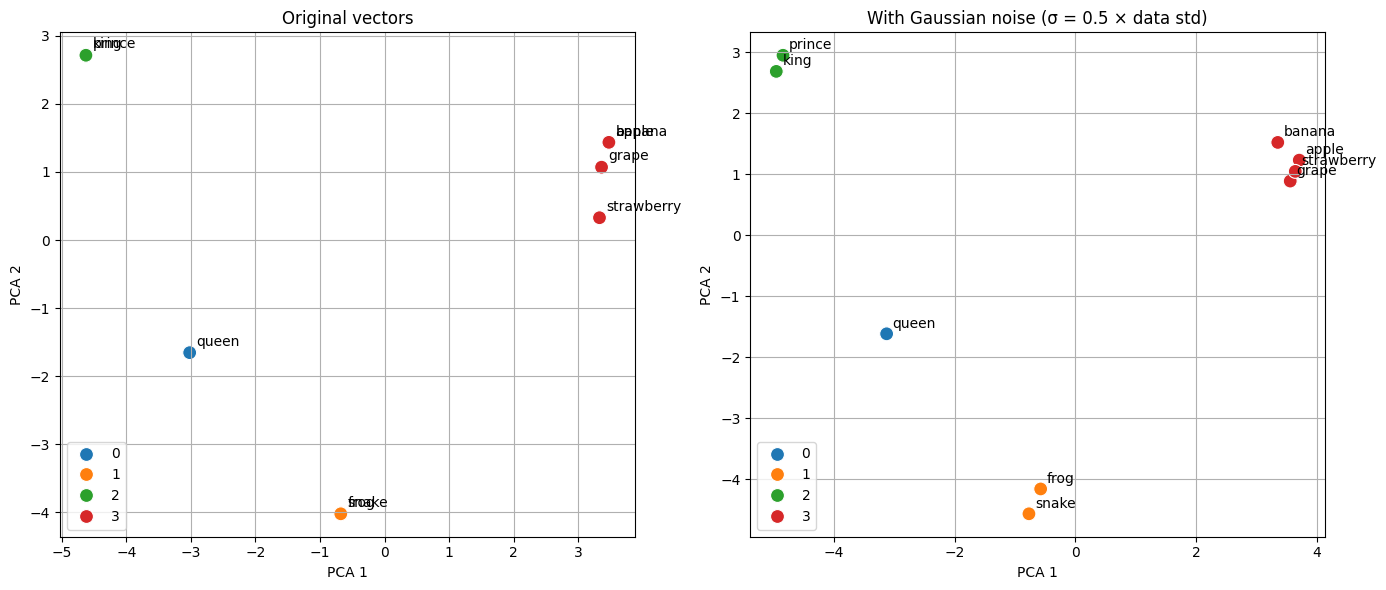

In [14]:
import numpy as np
import spacy
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import adjusted_rand_score

nlp = spacy.load("en_core_web_md")
words = ["apple", "banana", "grape", "king", "queen", "prince", "frog", "strawberry", "snake"]
X = np.array([nlp(w).vector for w in words])
k = 4

def cluster(vectors):
    return KMeans(n_clusters=k, random_state=0, n_init="auto").fit_predict(vectors)

def groups(words, labels):
    g = {}
    for w, l in zip(words, labels):
        g.setdefault(l, []).append(w)
    return sorted(sorted(v) for v in g.values())

base = cluster(X)
print("Baseline clusters:", groups(words, base))
print("Vector std per dimension (avg):", round(float(X.std()), 3))

# Add Gaussian noise scaled relative to the vectors' own spread
rng = np.random.default_rng(42)
sigma_data = X.std()
rows = []
for frac in [0.1, 0.25, 0.5, 1.0, 2.0]:
    aris = []
    for trial in range(20):
        Xn = X + rng.normal(0, frac * sigma_data, X.shape)
        aris.append(adjusted_rand_score(base, cluster(Xn)))
    aris = np.array(aris)
    rows.append({"noise (x data std)": frac,
                 "mean ARI": round(aris.mean(), 3),
                 "% runs identical to baseline": int((aris == 1).mean() * 100)})
print(pd.DataFrame(rows).to_string(index=False))

# One illustrative noisy run (noise = 0.5 x std) to show and plot
Xn = X + np.random.default_rng(0).normal(0, 0.5 * sigma_data, X.shape)
noisy = cluster(Xn)
print("\nNoisy (0.5 std) clusters:", groups(words, noisy))
print("ARI vs baseline:", round(adjusted_rand_score(base, noisy), 3))

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
for ax, V, lab, title in [(axes[0], X, base, "Original vectors"),
                           (axes[1], Xn, noisy, "With Gaussian noise (σ = 0.5 × data std)")]:
    P = PCA(n_components=2).fit_transform(V)
    sns.scatterplot(x=P[:, 0], y=P[:, 1], hue=lab, palette="tab10", s=100, ax=ax)
    for i, w in enumerate(words):
        ax.text(P[i, 0] + 0.1, P[i, 1] + 0.1, w)
    ax.set_title(title); ax.set_xlabel("PCA 1"); ax.set_ylabel("PCA 2"); ax.grid(True)
plt.tight_layout()
plt.show()